# 1, Calculation & 2, Prediction

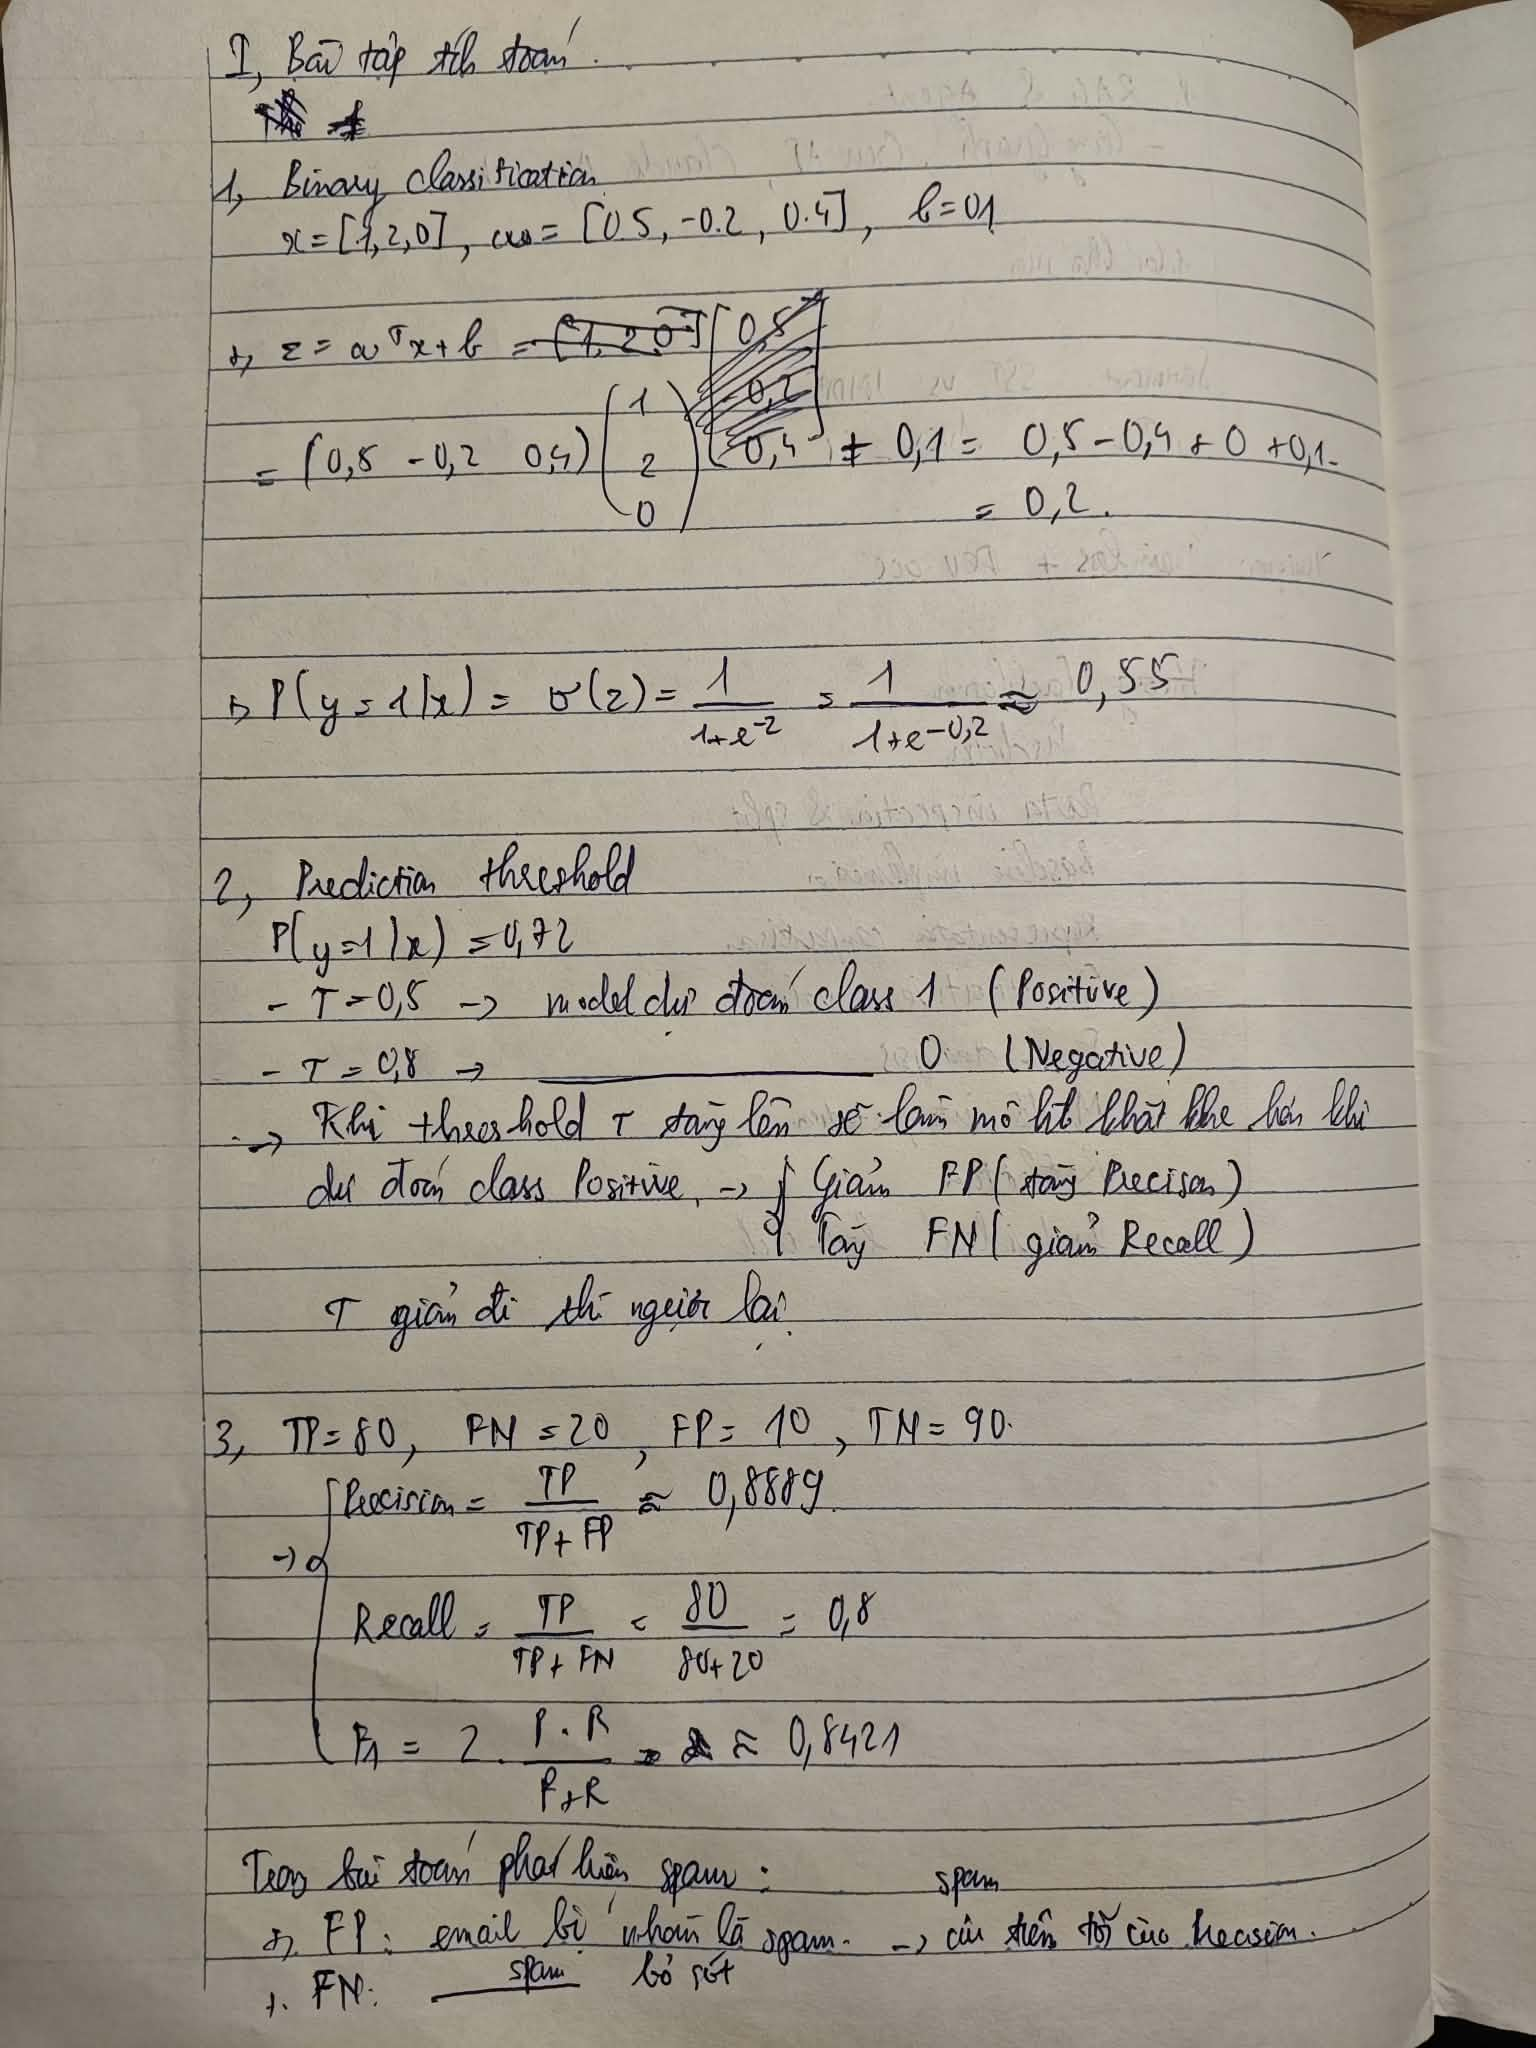

  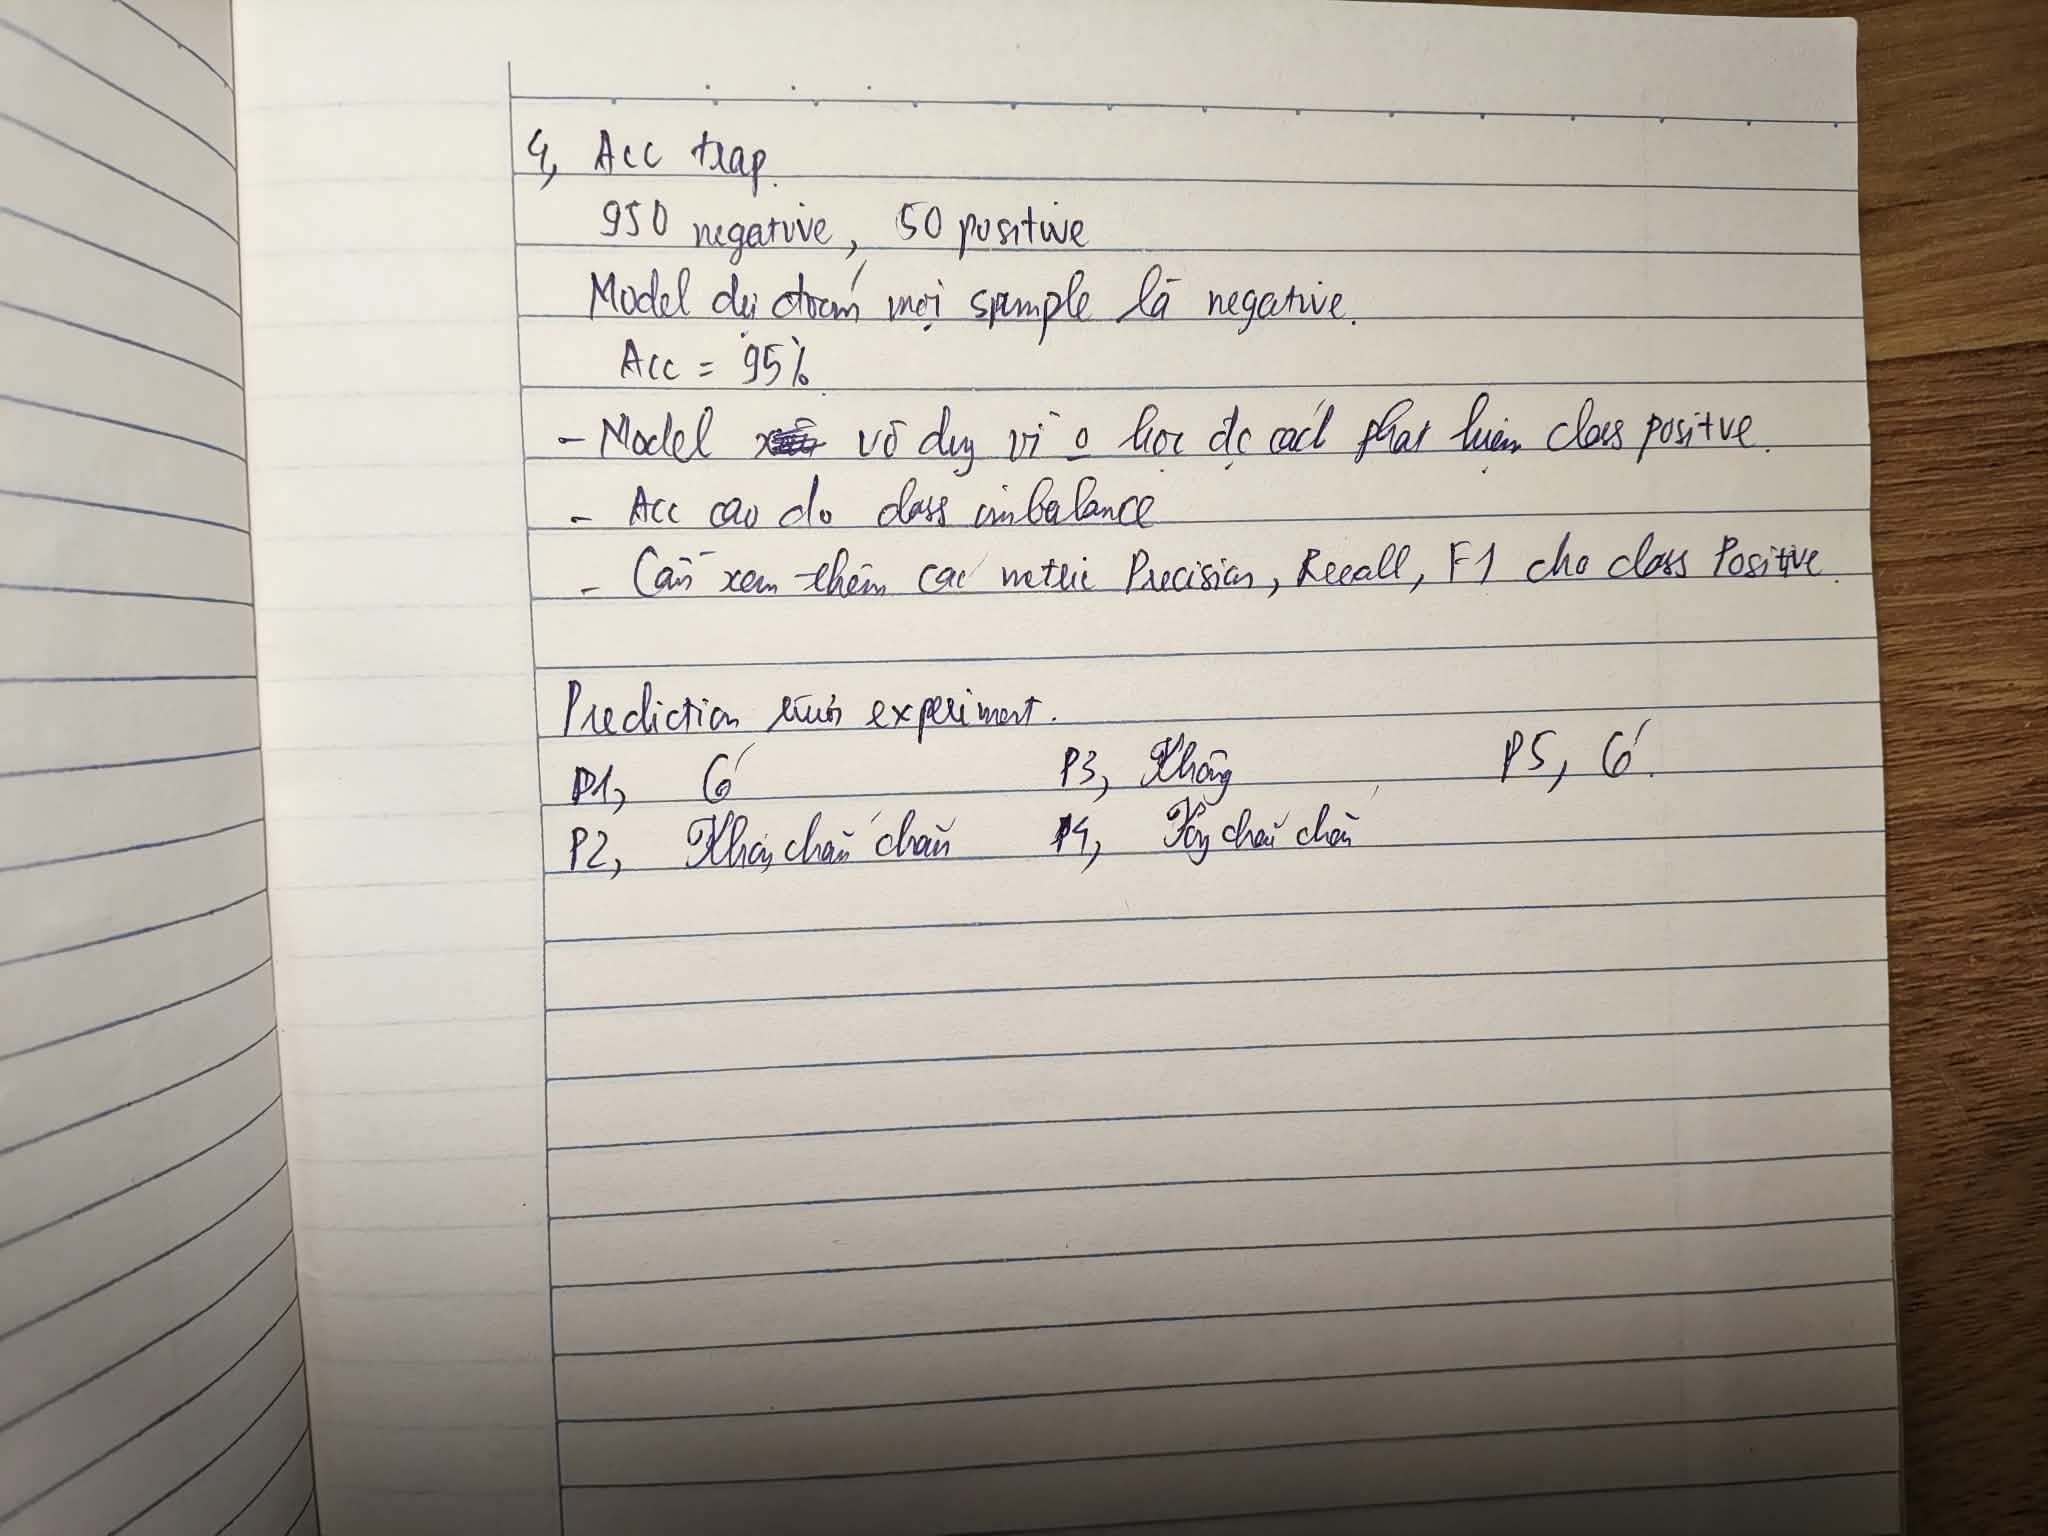

# 3, Data inspection & split

In [1]:
!pwd

/content


In [2]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/Lab4

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/Lab4


In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

# Tải dữ liệu IMDb từ Hugging Face
imdb_hf = load_dataset("stanfordnlp/imdb", name="plain_text")

In [4]:
df_train_raw = pd.DataFrame(imdb_hf['train'])
df_test_raw = pd.DataFrame(imdb_hf['test'])
df_all = pd.concat([df_train_raw, df_test_raw], ignore_index=True)

print("Kích thước tập Train gốc:", df_train_raw.shape)
print("Kích thước tập Test gốc:", df_test_raw.shape)
df_train_raw.head()

Kích thước tập Train gốc: (25000, 2)
Kích thước tập Test gốc: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


Tổng số samples (Train + Test): 50000
Số classes: 2 (0: Negative, 1: Positive)
Missing text: 0 | Missing labels: 0
Số văn bản bị trùng lặp (Duplicate documents): 418

Thống kê độ dài văn bản (số từ):
min        4.00000
mean     231.15694
50%      173.00000
max     2470.00000
Name: word_count, dtype: float64

Bảng phân phối class trên tập Train:
              Count  Percentage (%)
label                              
Negative (0)  12500            50.0
Positive (1)  12500            50.0


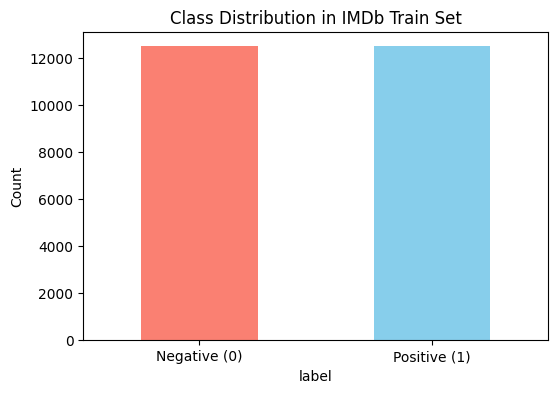

In [5]:
# 1. Số samples và số classes
print("Tổng số samples (Train + Test):", len(df_all))
print("Số classes:", df_all['label'].nunique(), "(0: Negative, 1: Positive)")

# 2. Missing text & Missing labels
missing_text = df_all['text'].isnull().sum() + (df_all['text'].str.strip() == "").sum()
missing_label = df_all['label'].isnull().sum()
print(f"Missing text: {missing_text} | Missing labels: {missing_label}")

# 3. Duplicate documents
duplicates = df_all.duplicated(subset=['text']).sum()
print("Số văn bản bị trùng lặp (Duplicate documents):", duplicates)

# 4. Độ dài văn bản (tính theo số từ)
df_all['word_count'] = df_all['text'].apply(lambda x: len(x.split()))
print("\nThống kê độ dài văn bản (số từ):")
print(df_all['word_count'].describe()[['min', 'mean', '50%', 'max']])

# 5. Bảng phân phối Class (trên tập Train gốc)
class_counts = df_train_raw['label'].value_counts().rename(index={0: 'Negative (0)', 1: 'Positive (1)'})
class_pct = df_train_raw['label'].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct.values})
print("\nBảng phân phối class trên tập Train:")
print(dist_df)

# 6. Vẽ biểu đồ phân phối class
class_counts.plot(kind='bar', color=['salmon', 'skyblue'], rot=0, figsize=(6, 4))
plt.title("Class Distribution in IMDb Train Set")
plt.ylabel("Count")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

# Xóa các dòng trùng lặp để tránh trùng mẫu giữa các tập
df_train_clean = df_train_raw.drop_duplicates(subset=['text']).reset_index(drop=True)
df_test_clean = df_test_raw.drop_duplicates(subset=['text']).reset_index(drop=True)

# Loại bỏ những câu trong tập Test vô tình xuất hiện trong tập Train
df_test_clean = df_test_clean[~df_test_clean['text'].isin(df_train_clean['text'])].reset_index(drop=True)

# Chia tập Train thành Train (80%) và Validation (20%) có stratify để giữ nguyên tỷ lệ nhãn
X_train, X_val, y_train, y_val = train_test_split(
    df_train_clean['text'],
    df_train_clean['label'],
    test_size=0.2,
    random_state=42,
    stratify=df_train_clean['label']
)

X_test = df_test_clean['text']
y_test = df_test_clean['label']

print(f"Số mẫu Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Số mẫu Train: 19923 | Validation: 4981 | Test: 24678


- Bộ dữ liệu IMDb hoàn toàn cân bằng (không bị class imbalance)
- Vì sao fit TF-IDF trên toàn bộ dataset trước khi split lại là data leakage?:
  - Khi gọi fit() của TF-IDF trên toàn bộ bộ dữ liệu trước khi chia tập, bộ từ điển (vocabulary) và trọng số nghịch đảo tần suất văn bản ($\text{IDF} = \log \frac{N}{df_t}$) đã được tính toán dựa trên cả các văn bản thuộc tập Test.
  - Điều này làm cho thông tin thống kê về phân phối từ vựng của tập dữ liệu kiểm tra (vốn phải hoàn toàn "vô hình" trong lúc huấn luyện) bị rò rỉ vào giai đoạn biểu diễn đặc trưng của tập Train, dẫn đến kết quả đánh giá trên tập Test bị ảo (quá lạc quan) và không phản ánh đúng khả năng tổng quát hóa của mô hình trên dữ liệu thực tế mới. Quy trình bắt buộc là chỉ fit_transform trên tập Train, sau đó dùng bộ vectorizer đó để transform trên tập Validation và Test.

# 4, Baseline Implementation

## Model A — TF-IDF + Logistic Regression

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Fit TF-IDF trên tập TRAIN, chỉ transform trên VAL và TEST
tfidf_vec = TfidfVectorizer(max_features=20000, stop_words=None)

start_time = time.time()
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_val_tfidf = tfidf_vec.transform(X_val)
X_test_tfidf = tfidf_vec.transform(X_test)

# 2. Huấn luyện Logistic Regression
lr_baseline = LogisticRegression(max_iter=1000, random_state=42)
lr_baseline.fit(X_train_tfidf, y_train)
train_time_baseline = time.time() - start_time

# 3. Dự đoán và tính toán các chỉ số trên tập Test
y_pred_baseline = lr_baseline.predict(X_test_tfidf)

vocab_size_baseline = len(tfidf_vec.vocabulary_)
acc_base = accuracy_score(y_test, y_pred_baseline)
prec_base = precision_score(y_test, y_pred_baseline)
rec_base = recall_score(y_test, y_pred_baseline)
f1_base = f1_score(y_test, y_pred_baseline)

print(f"Training time: {train_time_baseline:.2f} giây")
print(f"Vocabulary size: {vocab_size_baseline}")
print(f"Accuracy : {acc_base:.4f}")
print(f"Precision: {prec_base:.4f}")
print(f"Recall   : {rec_base:.4f}")
print(f"F1-score : {f1_base:.4f}")

Training time: 8.82 giây
Vocabulary size: 20000
Accuracy : 0.8819
Precision: 0.8828
Recall   : 0.8824
F1-score : 0.8826


# 5, Representation Comparison

## Model B — Average Word2Vec + Logistic Regression

In [11]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.3 MB/s eta 0:00:00


In [12]:
from gensim.models import Word2Vec

# Tách từ cơ bản (chuyển về chữ thường và tách theo khoảng trắng)
train_tokens = [text.lower().split() for text in X_train]
val_tokens = [text.lower().split() for text in X_val]
test_tokens = [text.lower().split() for text in X_test]

# Huấn luyện Word2Vec chỉ trên tập Train
start_w2v = time.time()
w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4, seed=42)

# Hàm tính trung bình cộng vector từ cho mỗi văn bản
def get_avg_w2v(tokens_list, model, vector_size=100):
    vectors = []
    for tokens in tokens_list:
        valid_words = [model.wv[w] for w in tokens if w in model.wv]
        if len(valid_words) > 0:
            vectors.append(np.mean(valid_words, axis=0))
        else:
            vectors.append(np.zeros(vector_size))
    return np.array(vectors)

X_train_w2v = get_avg_w2v(train_tokens, w2v_model)
X_test_w2v = get_avg_w2v(test_tokens, w2v_model)

# Huấn luyện Logistic Regression trên Average Word2Vec
lr_w2v = LogisticRegression(max_iter=1000, random_state=42)
lr_w2v.fit(X_train_w2v, y_train)
train_time_w2v = time.time() - start_w2v

y_pred_w2v = lr_w2v.predict(X_test_w2v)

## Model C — TF-IDF + Linear SVM

In [14]:
from sklearn.svm import LinearSVC

# Model C: TF-IDF + Linear SVM
start_svm = time.time()
svm_clf = LinearSVC(random_state=42)
svm_clf.fit(X_train_tfidf, y_train)
train_time_svm = time.time() - start_svm

y_pred_svm = svm_clf.predict(X_test_tfidf)

In [15]:
# Tổng hợp bảng kết quả
results_df = pd.DataFrame([
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_baseline),
        "Precision": precision_score(y_test, y_pred_baseline),
        "Recall": recall_score(y_test, y_pred_baseline),
        "F1": f1_score(y_test, y_pred_baseline)
    },
    {
        "Representation": "Avg Word2Vec",
        "Classifier": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_w2v),
        "Precision": precision_score(y_test, y_pred_w2v),
        "Recall": recall_score(y_test, y_pred_w2v),
        "F1": f1_score(y_test, y_pred_w2v)
    },
    {
        "Representation": "TF-IDF",
        "Classifier": "Linear SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Precision": precision_score(y_test, y_pred_svm),
        "Recall": recall_score(y_test, y_pred_svm),
        "F1": f1_score(y_test, y_pred_svm)
    }
])

results_df.to_csv("results.csv", index=False)
results_df

,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.881919,0.882799,0.882372,0.882585
1,Avg Word2Vec,Logistic Regression,0.803023,0.800334,0.810587,0.805428
2,TF-IDF,Linear SVM,0.874017,0.880927,0.866661,0.873736


Tại sao hai representation (TF-IDF và Average Word2Vec) tạo ra kết quả khác nhau?

- TF-IDF (Sparse, Lexical Representation): Tạo ra vector thưa (sparse) có số chiều lớn bằng kích thước từ điển, giữ lại chính xác thông tin hiện diện của từng từ/cụm từ đặc trưng (lexical terms) và hạ trọng số các từ phổ biến. Trong bài toán phân loại cảm xúc IMDb, các tính từ cảm xúc mạnh như "excellent", "masterpiece", "terrible", "waste" là tín hiệu phân loại trực tiếp cực kỳ mạnh, giúp bộ phân loại tuyến tính gán trọng số riêng biệt cho từng từ và đạt độ chính xác cao hơn

- Average Word2Vec (Dense, Semantic Representation): Tạo ra vector đặc (dense) số chiều thấp (ví dụ 100 chiều) nắm bắt được ngữ nghĩa tương đồng giữa các từ. Tuy nhiên, một bài đánh giá phim IMDb dài trung bình hơn 200 từ; khi lấy trung bình cộng ($\vec{x} = \frac{1}{n}\sum_i \vec{w}_i$) toàn bộ các từ trong bài viết, vector của vài tính từ cảm xúc quan trọng bị "pha loãng" (washed out) bởi hàng trăm từ chức năng và từ mô tả cốt truyện trung tính, làm mất thông tin quan trọng và khiến kết quả thấp hơn. Ngoài ra, các từ trái nghĩa như "good" và "bad" thường xuất hiện trong ngữ cảnh giống nhau nên vector Word2Vec của chúng có thể khá gần nhau, gây khó khăn thêm cho bộ phân loại.

## Experiment 4 (Word Order)

In [16]:
s1 = "this movie is good"
s2 = "this movie is not good"

# Kiểm tra dự đoán với Average Word2Vec và TF-IDF Unigram
s1_w2v = get_avg_w2v([s1.split()], w2v_model)
s2_w2v = get_avg_w2v([s2.split()], w2v_model)
print(f"Avg Word2Vec - S1 ('{s1}') -> Dự đoán class: {lr_w2v.predict(s1_w2v)[0]} (Xác suất Pos: {lr_w2v.predict_proba(s1_w2v)[0][1]:.4f})")
print(f"Avg Word2Vec - S2 ('{s2}') -> Dự đoán class: {lr_w2v.predict(s2_w2v)[0]} (Xác suất Pos: {lr_w2v.predict_proba(s2_w2v)[0][1]:.4f})")

Avg Word2Vec - S1 ('this movie is good') -> Dự đoán class: 1 (Xác suất Pos: 0.9562)
Avg Word2Vec - S2 ('this movie is not good') -> Dự đoán class: 0 (Xác suất Pos: 0.2860)


Representation Average Word2Vec có hiểu được vai trò của từ "not" trong $S1$ và $S2$ không?

Không hiểu được cấu trúc phủ định. Phép lấy trung bình cộng $\vec{x} = \frac{1}{n}\sum_i \vec{w}_i$ có tính chất giao hoán (bag-of-words), tức là mất hoàn toàn thứ tự từ (word order) và quan hệ bổ ngữ. Từ "not" chỉ đơn thuần được cộng thêm vector của nó vào tổng chung chứ không hề đảo ngược dấu hay biến đổi ngữ nghĩa của vector từ "good" đứng ngay sau nó.

## Experiment 5 (N-gram Features)

In [17]:
# 1. Unigram (không giới hạn max_features để thấy sự thay đổi kích thước Vocabulary)
start_uni = time.time()
vec_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=5)
X_tr_uni = vec_uni.fit_transform(X_train)
X_te_uni = vec_uni.transform(X_test)
clf_uni = LogisticRegression(max_iter=1000).fit(X_tr_uni, y_train)
time_uni = time.time() - start_uni
f1_uni = f1_score(y_test, clf_uni.predict(X_te_uni))

# 2. Unigram + Bigram
start_bi = time.time()
vec_bi = TfidfVectorizer(ngram_range=(1, 2), min_df=5)
X_tr_bi = vec_bi.fit_transform(X_train)
X_te_bi = vec_bi.transform(X_test)
clf_bi = LogisticRegression(max_iter=1000).fit(X_tr_bi, y_train)
time_bi = time.time() - start_bi
f1_bi = f1_score(y_test, clf_bi.predict(X_te_bi))

ngram_df = pd.DataFrame([
    {"Features": "Unigram", "Vocabulary": len(vec_uni.vocabulary_), "F1": f1_uni, "Training time (s)": time_uni},
    {"Features": "Uni + Bigram", "Vocabulary": len(vec_bi.vocabulary_), "F1": f1_bi, "Training time (s)": time_bi}
])
print(ngram_df)

       Features  Vocabulary        F1  Training time (s)
0       Unigram       24395  0.881827           8.260791
1  Uni + Bigram      129876  0.889592          29.312278


Vì sao bigram có thể giúp classification nhưng đồng thời làm feature space lớn hơn?

- Giúp cải thiện phân loại: Bigram giữ lại được ngữ cảnh cục bộ của 2 từ liên tiếp, biến các cụm từ mang tính đảo chiều hoặc nhấn mạnh cảm xúc như "not good", "not bad", "very good" thành các đặc trưng (features) độc lập. Nhờ vậy, mô hình phân biệt được "not good" (tiêu cực) với "good" (tích cực) thay vì nhìn từng từ rời rạc.

- Làm không gian đặc trưng (feature space) phình to: Nếu từ điển Unigram có $V$ từ thì số lượng cặp từ Bigram tiềm năng có thể tăng lên tới bậc $O(V^2)$ (hoặc tăng gấp 4–6 lần số lượng đặc trưng thực tế trong tập dữ liệu sau khi lọc tần suất), dẫn đến ma trận đặc trưng rộng hơn, tốn bộ nhớ hơn và thời gian huấn luyện lâu hơn.

# 6, Quantitative Evaluation

True Positive (TP) : 10952
True Negative (TN) : 10812
False Positive (FP): 1454
False Negative (FN): 1460


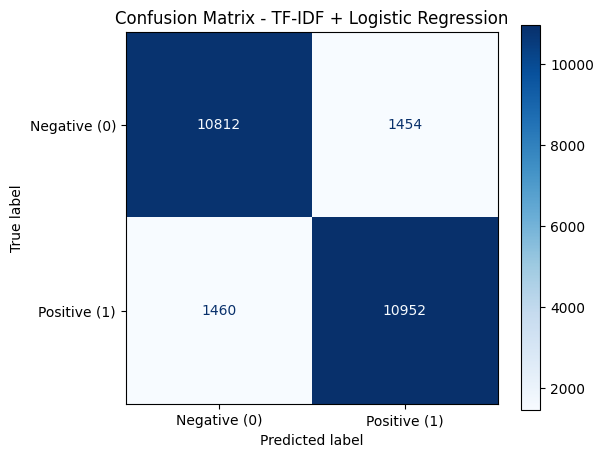

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Tính Confusion Matrix cho mô hình Baseline (TF-IDF + Logistic Regression)
cm = confusion_matrix(y_test, y_pred_baseline)
tn, fp, fn, tp = cm.ravel()

print(f"True Positive (TP) : {tp}")
print(f"True Negative (TN) : {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")

# Vẽ và lưu Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative (0)", "Positive (1)"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.savefig("confusion_matrix.png", bbox_inches='tight')
plt.show()

Class nào bị nhầm nhiều nhất & Loại error nào chiếm nhiều?

- Hai loại lỗi False Positive và False Negative khá cân bằng nhau
- lớp Negative bị nhầm thành Positive (False Positive) nhỉnh hơn một chút.

Metric nào phản ánh vấn đề đó?

- $FP > FN$ được phản ánh trực tiếp qua việc chỉ số Precision thấp hơn một chút so với Recall

# 7, Error Analysis

In [19]:
# Tạo bảng kết quả dự đoán trên tập Test
eval_df = pd.DataFrame({
    'text': X_test.values,
    'true_label': y_test.values,
    'pred_label': y_pred_baseline,
    'prob_pos': lr_baseline.predict_proba(X_test_tfidf)[:, 1]
})

# Lấy 3 mẫu dự đoán ĐÚNG và 3 mẫu dự đoán SAI
correct_samples = eval_df[eval_df['true_label'] == eval_df['pred_label']].head(3)
incorrect_samples = eval_df[eval_df['true_label'] != eval_df['pred_label']].head(5)

print("3 MẪU PHÂN LOẠI ĐÚNG")
for idx, row in correct_samples.iterrows():
    print(f"[True: {row['true_label']} | Pred: {row['pred_label']} | Prob(Pos): {row['prob_pos']:.3f}]\nText: {row['text'][:300]}...\n")

print("CÁC MẪU PHÂN LOẠI SAI TIÊU BIỂU")
for idx, row in incorrect_samples.iterrows():
    print(f"[True: {row['true_label']} | Pred: {row['pred_label']} | Prob(Pos): {row['prob_pos']:.3f}]\nText: {row['text'][:350]}...\n")

3 MẪU PHÂN LOẠI ĐÚNG
[True: 0 | Pred: 0 | Prob(Pos): 0.184]
Text: I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, C...

[True: 0 | Pred: 0 | Prob(Pos): 0.253]
Text: Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van Damme kick style, shooting battles with the 40 shell load shotgun, and even terrorist style bombs. All of this is entertaining and competently handled bu...

[True: 0 | Pred: 0 | Prob(Pos): 0.171]
Text: its a totally average film with a few semi-alright action sequences that make the plot seem a little better and remind the viewer of the classic van dam films. parts of the plot don't make sense and seem to be added in to use up time.

# 8, Model Interpretation

In [20]:
feature_names = np.array(tfidf_vec.get_feature_names_out())
weights = lr_baseline.coef_[0]

# Sắp xếp trọng số
top_pos_idx = np.argsort(weights)[-15:][::-1]
top_neg_idx = np.argsort(weights)[:15]

interp_df = pd.DataFrame({
    "Top Positive Feature": feature_names[top_pos_idx],
    "Pos Weight (w_i >> 0)": np.round(weights[top_pos_idx], 4),
    "Top Negative Feature": feature_names[top_neg_idx],
    "Neg Weight (w_i << 0)": np.round(weights[top_neg_idx], 4)
})

print("Top 15 Positive & Negative Features trong Logistic Regression:")
interp_df

Top 15 Positive & Negative Features trong Logistic Regression:


,Top Positive Feature,Pos Weight (w_i >> 0),Top Negative Feature,Neg Weight (w_i << 0)
0,great,7.0188,worst,-8.3299
1,excellent,5.4641,bad,-7.5758
2,perfect,4.4437,awful,-5.8127
3,wonderful,4.3957,waste,-5.7338
4,best,4.3895,boring,-5.6054
5,amazing,3.8553,poor,-4.9590
6,well,3.5069,terrible,-4.3378
7,love,3.4631,nothing,-4.2410
8,favorite,3.3566,worse,-4.1892
9,loved,3.3478,no,-4.0964


Những feature này có thực sự có ý nghĩa đối với task không?

Có ý nghĩa và trực quan đối với bài toán phân loại cảm xúc (Sentiment Classification). Các đặc trưng có $w_i \gg 0$ đều là các tính từ/động từ tán dương mạnh mẽ, trong khi các đặc trưng có $w_i \ll 0$ đều là các từ chê bai trực diện. Điều này chứng minh mô hình Logistic Regression kết hợp TF-IDF không học vẹt nhiễu ngẫu nhiên mà thực sự học được các từ khóa mang sắc thái cảm xúc cốt lõi của ngôn ngữ con người.

# 9, Reflection

TF-IDF (LAB 01) $\rightarrow$ N-gram (LAB 02) $\rightarrow$ Dense Word Embeddings (LAB 03) $\rightarrow$ LAB 04 (Representation) gồm:

Chia dữ liệu chống rò rỉ $\rightarrow$ Trích xuất đặc trưng $\rightarrow$ Phân loại $\rightarrow$ Đánh giá đa chiều và Phân tích lỗi.